# Simplified IMU-driven phase estimation

An extension of previous sims, using the same three-link FK/IK and gait trajectory.

The geometry is adjusted for a more natural-looking walk: upper/forearm lengths
have ratio `0.78/0.90 ≈ 0.87` (comparable to published greyhound humerus/radius
lengths), with a longer stance/swing step and a higher shoulder-to-ground distance.
The paw link is still an *illustrative effective* wrist-to-toe length, not a
measurement from a particular dog. All distances are normalized.

- A synthetic healthy dog supplies left and right leg reference motion.
- A *simulated* left-forearm IMU measures orientation and angular velocity with noise.
- A small reference-curve lookup estimates left gait phase, then adds a provisional half-cycle offset to command the right leg.
- The simulated right leg is kept only as comparison.

**Limitations:** This is an architecture proof of concept, not real IMU data, a trained ML model, or evidence that the approach works on Jax. The IMU signal is simplified and does not model speed changes or paw force/pressure. 


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

plt.rcParams["mathtext.fontset"] = "cm"
plt.rc("font", family="serif", size=10)
plt.rc('text', usetex=True)

L1, L2, L3 = 0.78, 0.90, 0.32
stride_half = 0.55
shoulder_height = 1.53
swing_lift = 0.25
duty_factor = 0.60

fps = 30
frequency = 0.80
cycles = 4
n_frames = round(cycles * fps / frequency)
time = np.arange(n_frames) / fps


In [2]:
def inverse_kinematics_3link(x, y, phi, L1, L2, L3, elbow_sign=1):
    """
    Toe (x,y), paw orientation phi -> shoulder, elbow, wrist angles.
    """

    # Required wrist location
    xw = np.asarray(x) - L3 * np.cos(phi)
    yw = np.asarray(y) - L3 * np.sin(phi)

    # Two-link IK for the wrist
    c2 = (xw**2 + yw**2 - L1**2 - L2**2) / (2 * L1 * L2)

    if np.any((c2 < -1 - 1e-9) | (c2 > 1 + 1e-9)):
        raise ValueError("Unreachable wrist target")

    c2 = np.clip(c2, -1.0, 1.0)
    s2 = elbow_sign * np.sqrt(1 - c2**2)

    theta2 = np.arctan2(s2, c2)

    theta1 = (
        np.arctan2(yw, xw)
        - np.arctan2(L2*s2, L1 + L2*c2)
    )

    theta3 = phi - theta1 - theta2

    return theta1, theta2, theta3


def forward_kinematics_3link(theta1, theta2, theta3, L1, L2, L3):
    """
    Reconstruct shoulder, elbow, wrist and toe coordinates.
    """

    # Shoulder
    sx, sy = 0.0, 0.0

    # Elbow
    ex = L1 * np.cos(theta1)
    ey = L1 * np.sin(theta1)

    # Wrist
    wx = ex + L2 * np.cos(theta1 + theta2)
    wy = ey + L2 * np.sin(theta1 + theta2)

    # Toe
    px = wx + L3 * np.cos(theta1 + theta2 + theta3)
    py = wy + L3 * np.sin(theta1 + theta2 + theta3)

    return sx, sy, ex, ey, wx, wy, px, py

In [3]:
def smoothstep(u):
    u = np.clip(u, 0.0, 1.0)
    return 3*u**2 - 2*u**3


def gait_trajectory(s):
    """
    Gait phase s -> toe position (x,y) and paw orientation phi.
    """

    s = np.asarray(s, dtype=float) % 1.0

    x = np.empty_like(s)
    y = np.empty_like(s)
    phi = np.empty_like(s)

    stance = s < duty_factor

    # -----------------------------------
    # STANCE
    # -----------------------------------

    u = s[stance] / duty_factor

    # Paw travels backward relative to the shoulder
    x[stance] = stride_half * (1 - 2*u)
    y[stance] = -shoulder_height

    # Flat through most of stance, then -45° push-off
    phi[stance] = (
        np.deg2rad(-45)
        * smoothstep((u - 0.75) / 0.25)
    )

    # -----------------------------------
    # SWING
    # -----------------------------------

    v = (s[~stance] - duty_factor) / (1 - duty_factor)

    # Paw returns forward
    x[~stance] = (
        -stride_half
        + 2*stride_half*smoothstep(v)
    )

    # Paw clears the ground
    y[~stance] = (
        -shoulder_height
        + swing_lift*np.sin(np.pi*v)
    )

    # Paw rotates -45° -> +15° -> 0°
    phi[~stance] = np.deg2rad(
        np.where(
            v <= 0.35,
            -45 + 60*smoothstep(v/0.35),
            15*(1 - smoothstep((v - 0.35)/0.65))
        )
    )

    return x, y, phi

In [4]:
# both forelimbs follow the same reference gait
# approximately half a cycle apart
s_left_true = (frequency * time) % 1
s_right_true = (s_left_true + 0.5) % 1

xL, yL, phiL = gait_trajectory(s_left_true)
left_angles = inverse_kinematics_3link(xL, yL, phiL, L1, L2, L3)

xR, yR, phiR = gait_trajectory(s_right_true)
right_angles_true = inverse_kinematics_3link(xR, yR, phiR, L1, L2, L3)

# A single IMU mounted on the LEFT FOREARM would measure angular velocity,
# and sensor fusion could provide an orientation estimate. The IMU does NOT
# directly measure the elbow joint angle.
beta_left = np.unwrap(left_angles[0] + left_angles[1])
beta_right = np.unwrap(right_angles_true[0] + right_angles_true[1])
omega_left = np.gradient(beta_left, 1/fps)
omega_right = np.gradient(beta_right, 1/fps)

# Simplified IMU measurement errors (illustrative, not measured specs).
rng = np.random.default_rng(7)
beta_measured = beta_left + np.deg2rad(1.0) * rng.normal(size=n_frames)
omega_measured = omega_left + np.deg2rad(3.0) * rng.normal(size=n_frames)


In [5]:
# Construct a noiseless angle/velocity reference over one gait cycle.
# This is a lookup of the same artificial gait, NOT a trained model.
phase_grid = np.linspace(0, 1, 400, endpoint=False)
x_ref, y_ref, phi_ref = gait_trajectory(phase_grid)
t1_ref, t2_ref, _ = inverse_kinematics_3link(
    x_ref, y_ref, phi_ref, L1, L2, L3
)
beta_ref = np.unwrap(t1_ref + t2_ref)
omega_ref = np.gradient(beta_ref, 1 / (frequency * len(phase_grid)))

# Find the closest point on the reference angle/velocity curve.
# Scaling keeps the angle and velocity terms comparable.
score = (
    ((beta_measured[:, None] - beta_ref) / np.deg2rad(15))**2
    + ((omega_measured[:, None] - omega_ref) / np.deg2rad(85))**2
)
s_left_est = phase_grid[np.argmin(score, axis=1)]
s_right_est = (s_left_est + 0.5) % 1

# Estimated phase -> original toe path -> original three-link IK
x_pred, y_pred, phi_pred = gait_trajectory(s_right_est)
right_angles_pred = inverse_kinematics_3link(
    x_pred, y_pred, phi_pred, L1, L2, L3
)

# Checks: phase estimation and IK/FK consistency
phase_error = ((s_left_est - s_left_true + 0.5) % 1) - 0.5
phase_rmse = np.sqrt(np.mean(phase_error**2))
_, _, _, _, _, _, x_fk, y_fk = forward_kinematics_3link(
    *right_angles_pred, L1, L2, L3
)
assert np.allclose(x_fk, x_pred, atol=1e-9)
assert np.allclose(y_fk, y_pred, atol=1e-9)

print(f"Phase RMSE: {phase_rmse:.4f} cycles ({phase_rmse*360:.1f} degrees)")
print("IK/FK reconstruction passed.")


Phase RMSE: 0.0246 cycles (8.9 degrees)
IK/FK reconstruction passed.


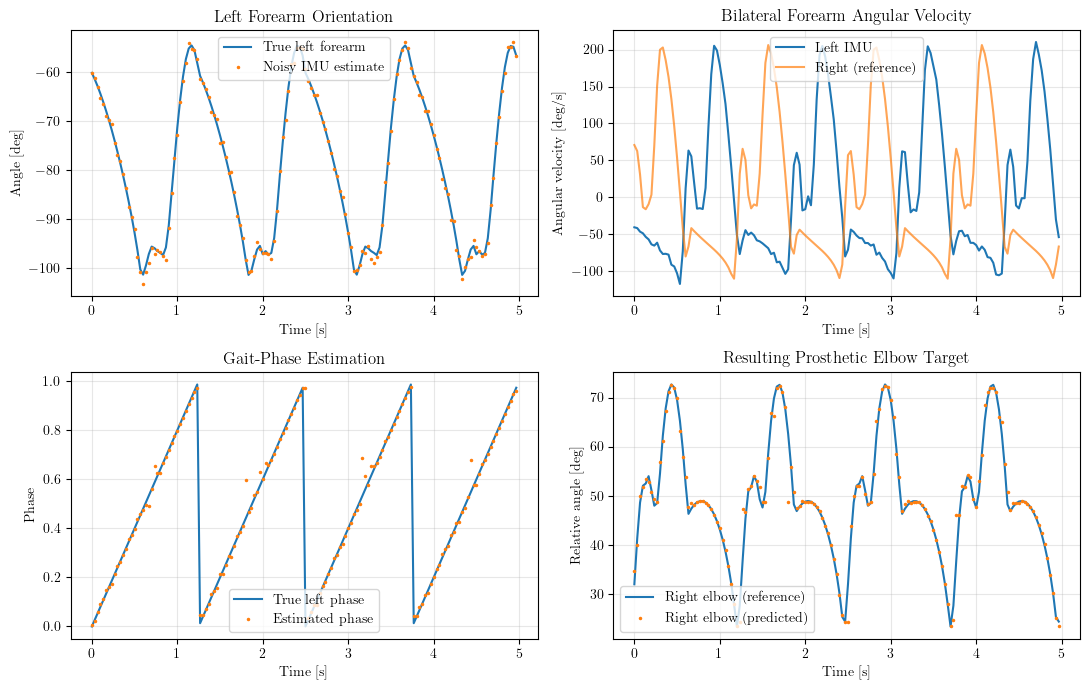

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].plot(time, np.rad2deg(beta_left), label="True left forearm")
axes[0, 0].plot(time, np.rad2deg(beta_measured), ".", ms=3,
                label="Noisy IMU estimate")
axes[0, 0].set(title="Left Forearm Orientation", xlabel="Time [s]", ylabel="Angle [deg]")
axes[0, 0].legend()

axes[0, 1].plot(time, np.rad2deg(omega_measured), label="Left IMU")
axes[0, 1].plot(time, np.rad2deg(omega_right), label="Right (reference)", alpha=0.7)
axes[0, 1].set(title="Bilateral Forearm Angular Velocity", xlabel="Time [s]",
               ylabel="Angular velocity [deg/s]")
axes[0, 1].legend()

axes[1, 0].plot(time, s_left_true, label="True left phase")
axes[1, 0].plot(time, s_left_est, ".", ms=3, label="Estimated phase")
axes[1, 0].set(title="Gait-Phase Estimation", xlabel="Time [s]", ylabel="Phase")
axes[1, 0].legend()

axes[1, 1].plot(time, np.rad2deg(right_angles_true[1]),
                label="Right elbow (reference)")
axes[1, 1].plot(time, np.rad2deg(right_angles_pred[1]), ".", ms=3,
                label="Right elbow (predicted)")
axes[1, 1].set(title="Resulting Prosthetic Elbow Target", xlabel="Time [s]",
               ylabel="Relative angle [deg]")
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:
fig, ax = plt.subplots(figsize=(7.5, 6))
reach = L1 + L2 + L3
ax.set(xlim=(-reach, reach), ylim=(-reach-0.1, 0.5),
       title="IMU-Driven Alternating Forelimbs")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.axhline(-shoulder_height, color="gray", linestyle="--")

left_line, = ax.plot([], [], "o-", color="red", lw=3, ms=6,
                     label="Left leg (synthetic)")
right_line, = ax.plot([], [], "o-", color="blue", lw=3, ms=6,
                      label="Right leg (IMU-driven)")
reference_line, = ax.plot([], [], "--", color="black", lw=1.5, alpha=0.6,
                          label="Right leg (reference)")
status = ax.text(0.02, 0.95, "", va="top", transform=ax.transAxes)
ax.legend(loc="upper right")

def leg_points(angles, frame):
    sx, sy, ex, ey, wx, wy, px, py = forward_kinematics_3link(
        angles[0][frame], angles[1][frame], angles[2][frame], L1, L2, L3
    )
    return [sx, ex, wx, px], [sy, ey, wy, py]

def update(frame):
    left_line.set_data(*leg_points(left_angles, frame))
    right_line.set_data(*leg_points(right_angles_pred, frame))
    reference_line.set_data(*leg_points(right_angles_true, frame))
    status.set_text(
        f"Left IMU: {np.rad2deg(beta_measured[frame]):.1f} deg, "
        f"{np.rad2deg(omega_measured[frame]):.0f} deg/s\n"
        f"Left phase: {s_left_est[frame]:.2f} (true {s_left_true[frame]:.2f})\n"
        f"Right target phase: {s_right_est[frame]:.2f}"
    )
    return left_line, right_line, reference_line, status

anim = FuncAnimation(fig, update, frames=n_frames, interval=1000/fps,
                     blit=True, repeat=True)
plt.close(fig)
HTML(anim.to_jshtml())


In [8]:
# Optional: export a GIF for the presentation (takes a few seconds).
anim.save("imu_alternating_legs.gif", writer=PillowWriter(fps=fps))
